# Bioquants - Assignment 6: Breast cancer gene expression analysis - Giuliana Paradiso (s319688)

## 1. Importing the gene expression dataset

In [1]:
# package imports
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore, ttest_ind
import numpy as np
import gzip
import zipfile
from statsmodels.stats.multitest import multipletests
import gseapy as gp

In [2]:
file_path = "GSE15852_series_matrix.txt.gz"
df = pd.read_csv(file_path, sep="\t", comment="!", index_col=0)
df = df.T
print(df.head())
print(df.shape)

ID_REF     1007_s_at   1053_at    117_at   121_at  1255_g_at  1294_at  \
GSM398074    1881.80   78.0658  1299.980  3086.72    353.890  248.635   
GSM398075    2317.51   61.3540   775.547  2335.15    303.653  356.766   
GSM398076    1553.86   80.0525  1103.740  3139.65    523.873  297.729   
GSM398077    1915.57   79.8518   762.005  2338.48    222.552  414.284   
GSM398078    1240.13  104.9330   820.822  2555.46    401.749  507.393   

ID_REF      1316_at   1320_at  1405_i_at  1431_at  ...  \
GSM398074  1381.120   31.2698   128.2760  724.081  ...   
GSM398075   745.809   59.8119    95.1752  101.793  ...   
GSM398076   983.263  130.4300    92.6413   97.817  ...   
GSM398077   608.709   67.1479    52.3703  238.117  ...   
GSM398078   962.763   71.2165   105.0160  196.212  ...   

ID_REF     AFFX-r2-Hs28SrRNA-5_at  AFFX-r2-Hs28SrRNA-M_at  \
GSM398074                1348.330                920.4560   
GSM398075                 884.752                875.7870   
GSM398076                 275

In [3]:
with gzip.open(file_path, "rt") as f:
    for line in f:
        if line.startswith("!Sample_source_name_ch1"):
            parts = line.strip().split("\t")[1:]  # salta il nome del campo
            source_names = [p.strip('"') for p in parts]
            break

# labels for tumor vs normal samples
groups = ["tumor" if "tumor" in s.lower() else "normal" for s in source_names]

print(len(groups))
print(groups[:10])
df_tumor = df.iloc[[i for i, g in enumerate(groups) if g == "tumor"]]
df_normal = df.iloc[[i for i, g in enumerate(groups) if g == "normal"]]

print("Tumor:", df_tumor.shape)
print("Normal:", df_normal.shape)


86
['normal', 'tumor', 'normal', 'tumor', 'normal', 'tumor', 'normal', 'tumor', 'normal', 'tumor']
Tumor: (43, 22283)
Normal: (43, 22283)


## 2. Quality control checks

### Removing samples with missing values

In [4]:
# total number of missing values in the dataset
total_missing = df.isnull().sum().sum()
print("Total missing values:", total_missing)

Total missing values: 0


### Outliers detection and removal

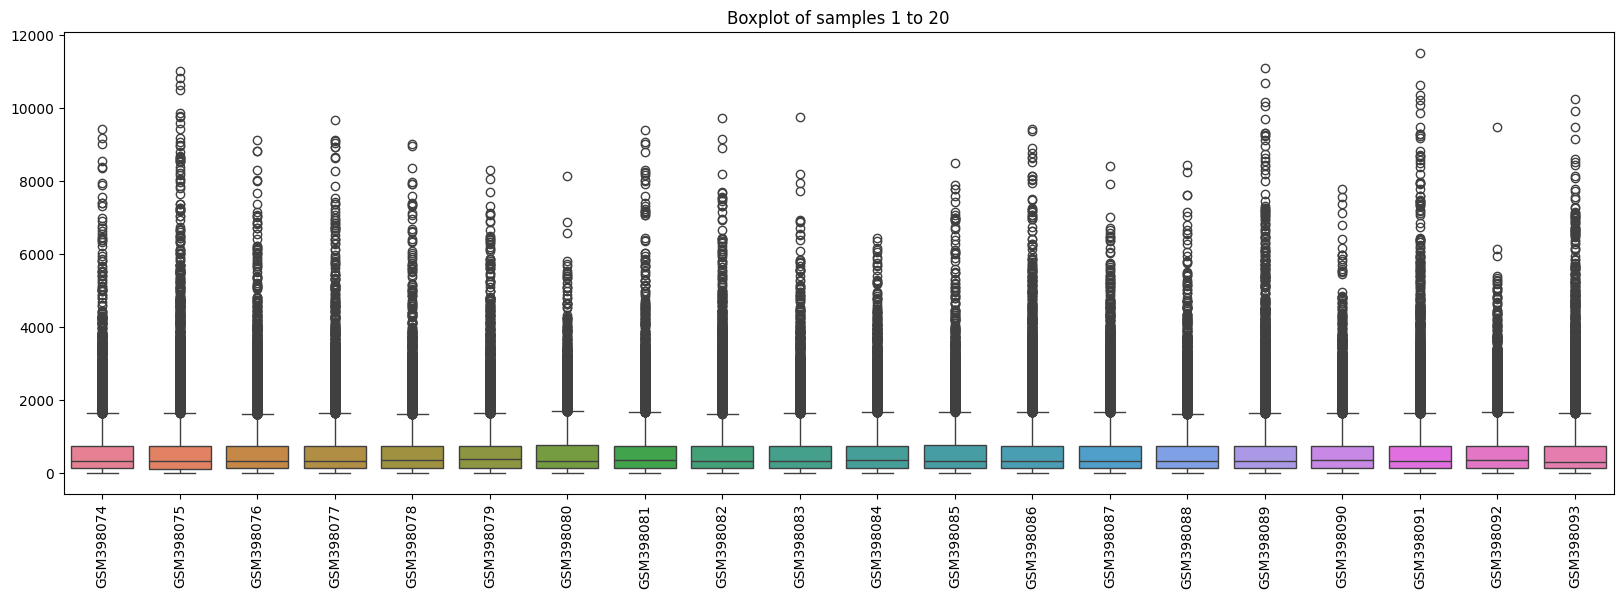

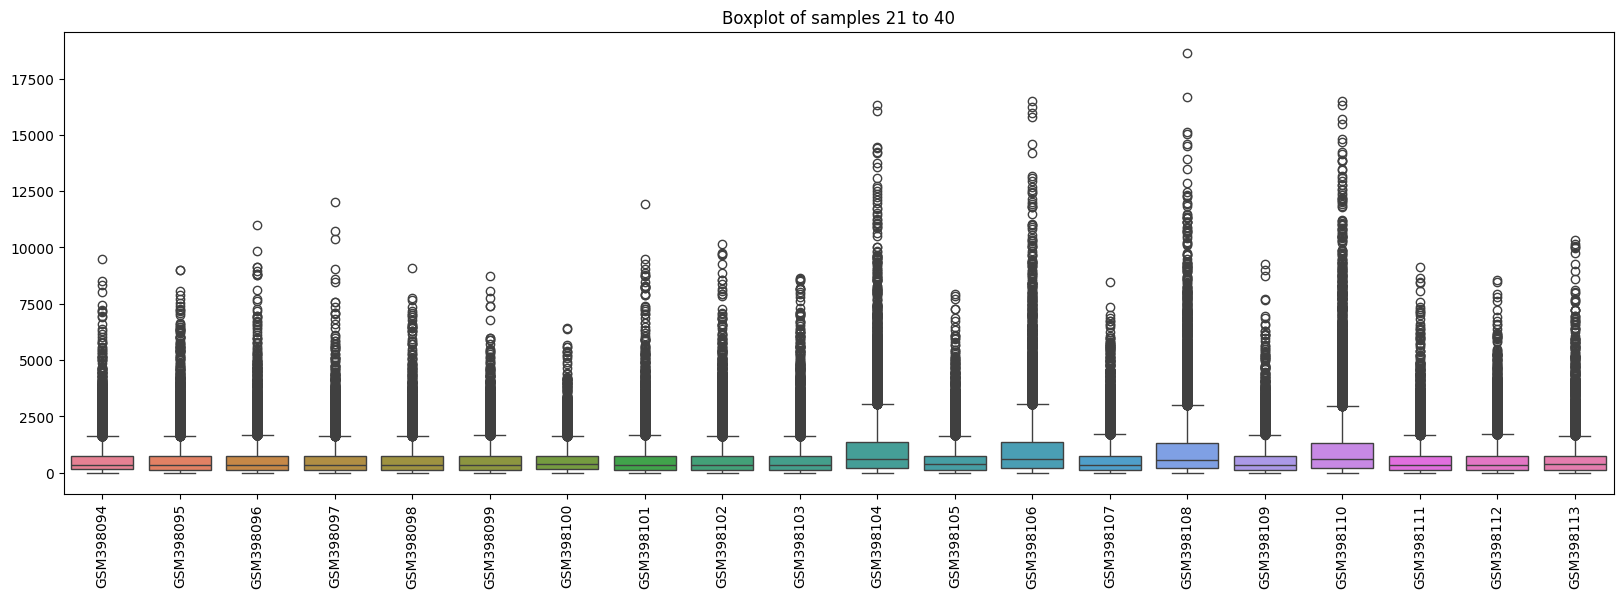

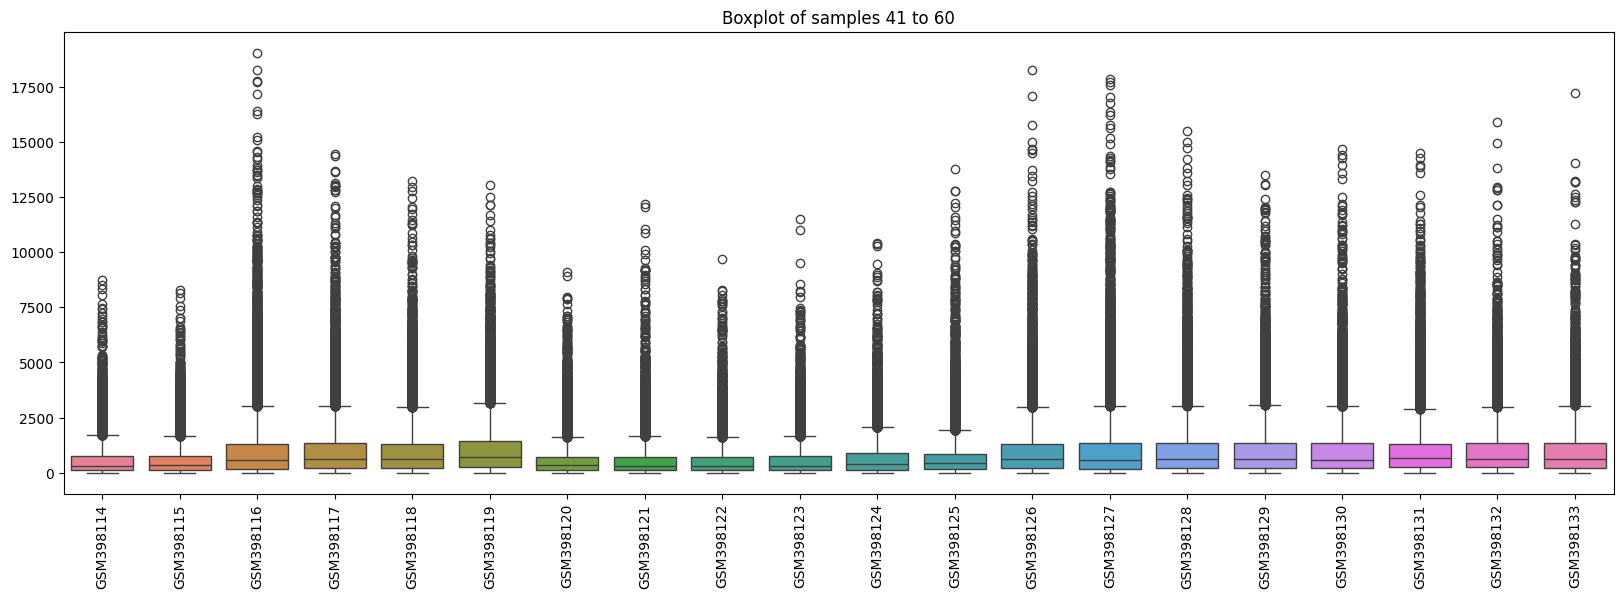

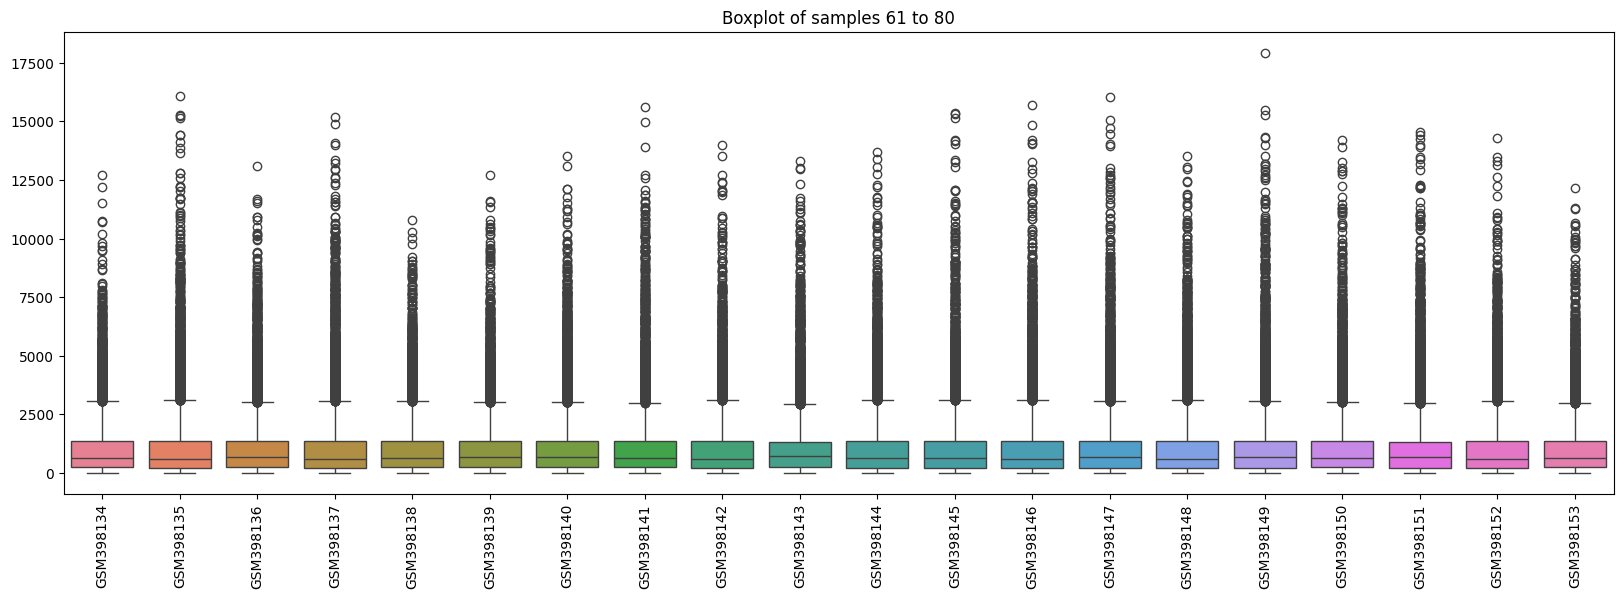

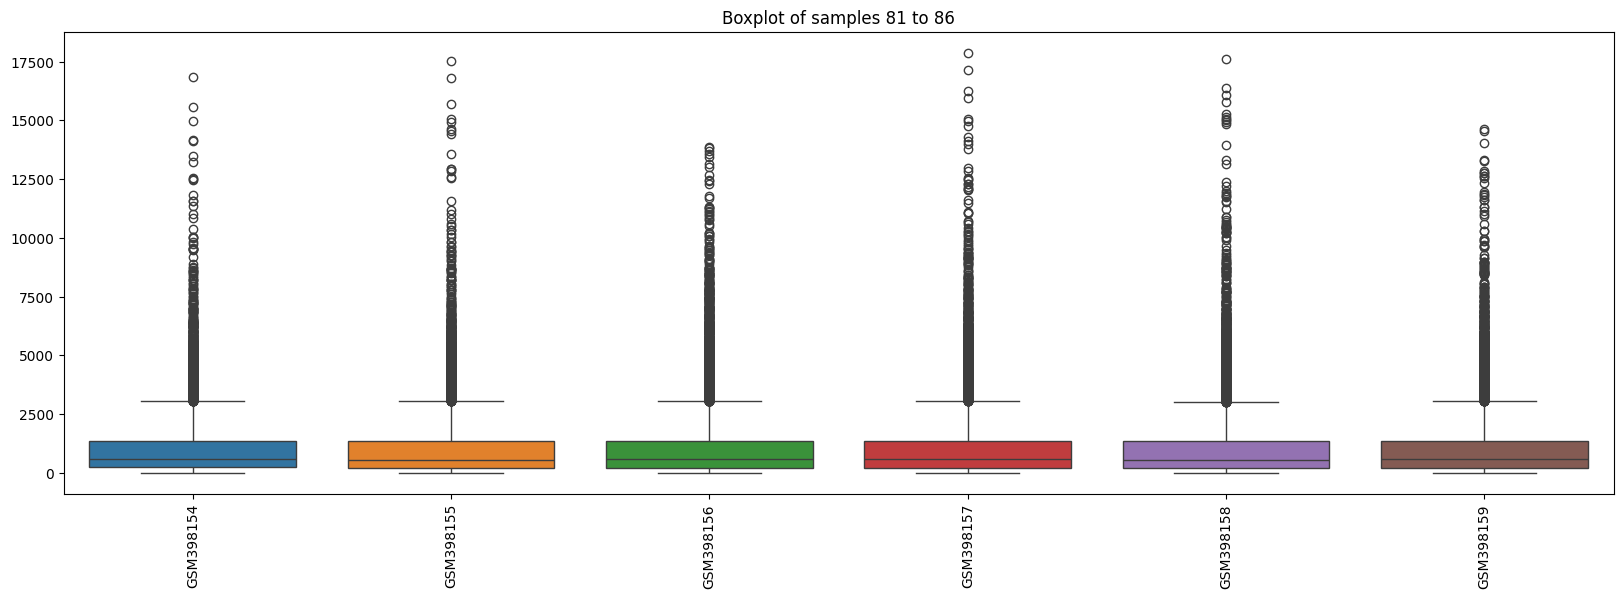

In [ ]:
for i in range(0, df.shape[0], 20):
    plt.figure(figsize=(20,6))
    sns.boxplot(data=df.iloc[i:i+20].T)
    plt.xticks(rotation=90)
    plt.title(f"Boxplot of samples {i+1} to {min(i+20, df.shape[0])}")
    plt.show()


In [6]:
z_scores = np.abs(zscore(df, axis=1)) 
mean_z_scores = z_scores.mean(axis=1)
outliers = mean_z_scores[mean_z_scores > 3]
print("Outlier samples:", outliers)

Outlier samples: Series([], dtype: float64)


## 3. Statistical analysis

### T-test

In [7]:
t_stats = []
p_values = []

genes = df.columns

for gene in genes:
    tumor_values = df_tumor[gene]
    normal_values = df_normal[gene]

    t_stat, p_val = ttest_ind(tumor_values, normal_values, equal_var=False, nan_policy="omit")
    t_stats.append(t_stat)
    p_values.append(p_val)

# results DataFrame
results = pd.DataFrame({"gene": genes, "t_statistic": t_stats, "p_value": p_values})
print(results)
print("Number of genes tested:", results.shape[0])

                  gene  t_statistic       p_value
0            1007_s_at     5.899585  1.351400e-07
1              1053_at    -1.589981  1.158527e-01
2               117_at    -2.815299  6.075523e-03
3               121_at    -1.081513  2.825643e-01
4            1255_g_at     0.082497  9.344581e-01
...                ...          ...           ...
22278   AFFX-ThrX-5_at     1.172223  2.457607e-01
22279   AFFX-ThrX-M_at    -0.014933  9.881217e-01
22280  AFFX-TrpnX-3_at    -0.727113  4.702004e-01
22281  AFFX-TrpnX-5_at     0.648072  5.190349e-01
22282  AFFX-TrpnX-M_at    -0.387243  6.996883e-01

[22283 rows x 3 columns]
Number of genes tested: 22283


### Benjamini-Hochberg correction

In [ ]:
reject, pvals_corrected, _, _ = multipletests(results["p_value"], alpha=0.05, method="fdr_bh")
results["p_adj"] = pvals_corrected
results["significant"] = reject
print(results)
deg = results[results["p_adj"] < 0.05]
print("Number of differentially expressed genes:", deg.shape[0])

                  gene  t_statistic       p_value     p_adj  significant
0            1007_s_at     5.899585  1.351400e-07  0.000018         True
1              1053_at    -1.589981  1.158527e-01  0.373057        False
2               117_at    -2.815299  6.075523e-03  0.069426        False
3               121_at    -1.081513  2.825643e-01  0.571104        False
4            1255_g_at     0.082497  9.344581e-01  0.975281        False
...                ...          ...           ...       ...          ...
22278   AFFX-ThrX-5_at     1.172223  2.457607e-01  0.533390        False
22279   AFFX-ThrX-M_at    -0.014933  9.881217e-01  0.996287        False
22280  AFFX-TrpnX-3_at    -0.727113  4.702004e-01  0.722561        False
22281  AFFX-TrpnX-5_at     0.648072  5.190349e-01  0.754296        False
22282  AFFX-TrpnX-M_at    -0.387243  6.996883e-01  0.862343        False

[22283 rows x 5 columns]
Number of differentially expressed genes: 1667


## 4. Functional enrichment analysis

In [9]:
# file path
annot_zip = "GPL96-57554.txt.zip"

# file estraction
with zipfile.ZipFile(annot_zip, "r") as z:
    fname = z.namelist()[0]
    with z.open(fname) as f:
        annot = pd.read_csv(f, sep="\t", comment="#", low_memory=False)

print(annot.head())
print(annot.columns)

          ID  GB_ACC SPOT_ID Species Scientific Name Annotation Date  \
0  1007_s_at  U48705     NaN            Homo sapiens     Oct 6, 2014   
1    1053_at  M87338     NaN            Homo sapiens     Oct 6, 2014   
2     117_at  X51757     NaN            Homo sapiens     Oct 6, 2014   
3     121_at  X69699     NaN            Homo sapiens     Oct 6, 2014   
4  1255_g_at  L36861     NaN            Homo sapiens     Oct 6, 2014   

       Sequence Type                  Sequence Source  \
0  Exemplar sequence  Affymetrix Proprietary Database   
1  Exemplar sequence                          GenBank   
2  Exemplar sequence  Affymetrix Proprietary Database   
3  Exemplar sequence                          GenBank   
4  Exemplar sequence  Affymetrix Proprietary Database   

                                  Target Description Representative Public ID  \
0  U48705 /FEATURE=mRNA /DEFINITION=HSU48705 Huma...                   U48705   
1  M87338 /FEATURE= /DEFINITION=HUMA1SBU Human re...          

In [10]:
# mapping probe IDs to gene symbols using the GPL96 annotation
annot = annot[["ID", "Gene Symbol"]]
annot = annot.dropna()
annot = annot[annot["Gene Symbol"] != ""]

# dictionary probe -> gene
probe_to_gene = dict(zip(annot["ID"], annot["Gene Symbol"]))

deg_probes = deg["gene"]
# mapping each probe to its corresponding gene symbol
deg_genes = deg_probes.map(probe_to_gene)
deg_genes = deg_genes.dropna()
gene_list = deg_genes.unique().tolist()
print("Number of mapped genes for enrichment:", len(gene_list))
print(gene_list)

Number of mapped genes for enrichment: 1398
['DDR1 /// MIR4640', 'CBX3', 'APP', 'DSP', 'RAD21', 'MARCKSL1', 'NUCB1', 'CALM1 /// CALM2 /// CALM3', 'TOMM20', 'DNAJB1', 'XBP1', 'SPTBN1', 'CD81', 'GLO1', 'GSN', 'GOT2', 'ACTR1A', 'ACTR2', 'GPX1', 'RAN', 'HNRNPC', 'MIR636 /// SRSF2', 'NFE2L1', 'LAMC1', 'ANXA5', 'PEA15', 'ECH1', 'LAMP2', 'SCD', 'EPRS', 'PRDX6', 'DHCR24', 'S100A10', 'MIR1292 /// NOP56 /// SNORD110 /// SNORD57 /// SNORD86', 'EPAS1', 'FKBP4', 'PALLD', 'CCT3 /// LOC101927137', 'TACC1', 'BTG1', 'RERE', 'HMGN1', 'HMGN1 /// LOC101927733', 'ABLIM1', 'PPIB', 'LOC101928061 /// SERP1', 'TSPAN3', 'TAX1BP1', 'MDH1', 'SERPING1', 'ACTR3', 'SSR4', 'CD9', 'TXNIP', 'ANXA1', 'PAICS', 'EIF5B', 'CD99', 'LDHB', 'HNRNPH1', 'BLCAP', 'HADH', 'DUSP1', 'STOM', 'SMARCC1', 'LGALS1', 'GPX4', 'CSE1L', 'PGD', 'CDH1', 'ECHS1', 'PLP2', 'SSB', 'TIMP3', 'YBX3', 'IDH1', 'PCNA', 'CTBP2', 'ARIH2', 'ATP1B1', 'SREBF2', 'SRP9', 'PSMA5', 'FDPS', 'HNRNPAB', 'DAB2 /// LOC101926921', 'SDC1', 'TOP2A', 'ANXA4', 'SEPT11', '

### GO Biological Process enrichment

In [11]:
go_results = gp.enrichr(gene_list=gene_list, gene_sets="GO_Biological_Process_2021", organism="Human", outdir=None, cutoff=0.05)
go_df = go_results.results
go_significant = go_df[go_df["Adjusted P-value"] < 0.05]
print("Significant GO Biological Processes:", go_significant.shape[0])
# top 10 GO terms based on Adjusted P-value
top_go = go_significant.sort_values("Adjusted P-value").head(10)
print(top_go[["Term", "Overlap", "Adjusted P-value", "Genes"]])

Significant GO Biological Processes: 255
                                                Term Overlap  \
0  negative regulation of cellular process (GO:00...  81/566   
1            regulation of angiogenesis (GO:0045765)  40/203   
2  negative regulation of apoptotic process (GO:0...  70/485   
3  regulation of cell population proliferation (G...  97/764   
4       regulation of apoptotic process (GO:0042981)  93/742   
5  negative regulation of programmed cell death (...  57/381   
6  negative regulation of blood vessel morphogene...   21/78   
7  regulation of fat cell differentiation (GO:004...   21/80   
8   negative regulation of angiogenesis (GO:0016525)   22/87   
9  extracellular structure organization (GO:0043062)  38/216   

   Adjusted P-value                                              Genes  
0          0.000002  APP;BTG1;PLXND1;FHL1;PDE3B;PTEN;JADE1;PTPRK;CL...  
1          0.000004  SP100;SPARC;BTG1;FLT1;PLXND1;NPR1;PDE3B;TWIST1...  
2          0.000007  CITED2;APIP;FH

### KEGG pathway enrichment

In [ ]:
kegg_results = gp.enrichr(gene_list=gene_list, gene_sets="KEGG_2021_Human", organism="Human", outdir=None, cutoff=0.05)
kegg_df = kegg_results.results
kegg_significant = kegg_df[kegg_df["Adjusted P-value"] < 0.05]
print("Significant KEGG pathways:", kegg_significant.shape[0])
# top 10 KEGG pathways based on Adjusted P-value
top_kegg = kegg_significant.sort_values("Adjusted P-value").head(10)
print(top_kegg[["Term", "Overlap", "Adjusted P-value", "Genes"]])

Significant KEGG pathways: 44
                                         Term Overlap  Adjusted P-value  \
0                      PPAR signaling pathway   22/74          0.000001   
1                     Proteoglycans in cancer  37/205          0.000010   
2                      Fatty acid degradation   15/43          0.000010   
3                       Propanoate metabolism   13/34          0.000016   
4                         Pyruvate metabolism   15/47          0.000024   
5                              Focal adhesion  34/201          0.000070   
6                    ECM-receptor interaction   20/88          0.000093   
7                                   Mitophagy   16/68          0.000525   
8  Valine, leucine and isoleucine degradation   13/48          0.000591   
9                   Citrate cycle (TCA cycle)   10/30          0.000686   

                                               Genes  
0  GK;ACSL1;ADIPOQ;LPL;NR1H3;ACSL3;SORBS1;FABP1;R...  
1  SDC4;SDC2;ITGB3;HSPB2;TWIST1;PI

## 5. Visualization of the results

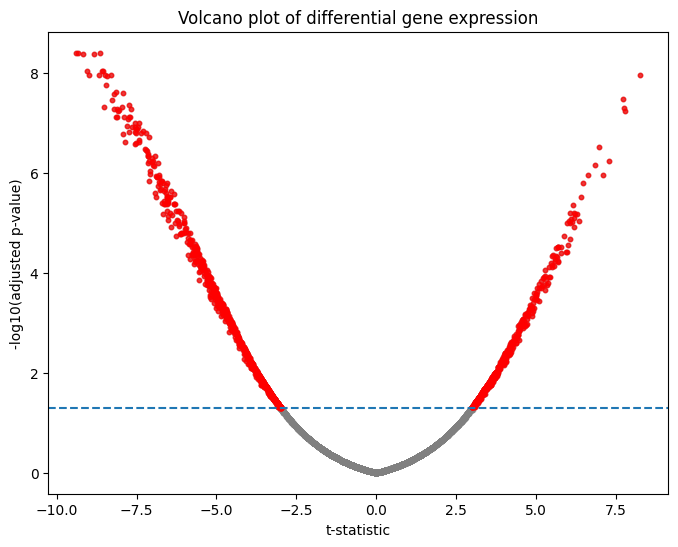

In [ ]:
# volcano plot
plt.figure(figsize=(8, 6))

# scatter all genes
plt.scatter(results["t_statistic"], -np.log10(results["p_adj"]), color="gray", alpha=0.5, s=10)

# highlight significant genes
sig = results["significant"]
plt.scatter(results.loc[sig, "t_statistic"], -np.log10(results.loc[sig, "p_adj"]), color="red", alpha=0.7, s=10)

# significance threshold line
plt.axhline(-np.log10(0.05), linestyle="--")

plt.xlabel("t-statistic")
plt.ylabel("-log10(adjusted p-value)")
plt.title("Volcano plot of differential gene expression")
plt.show()


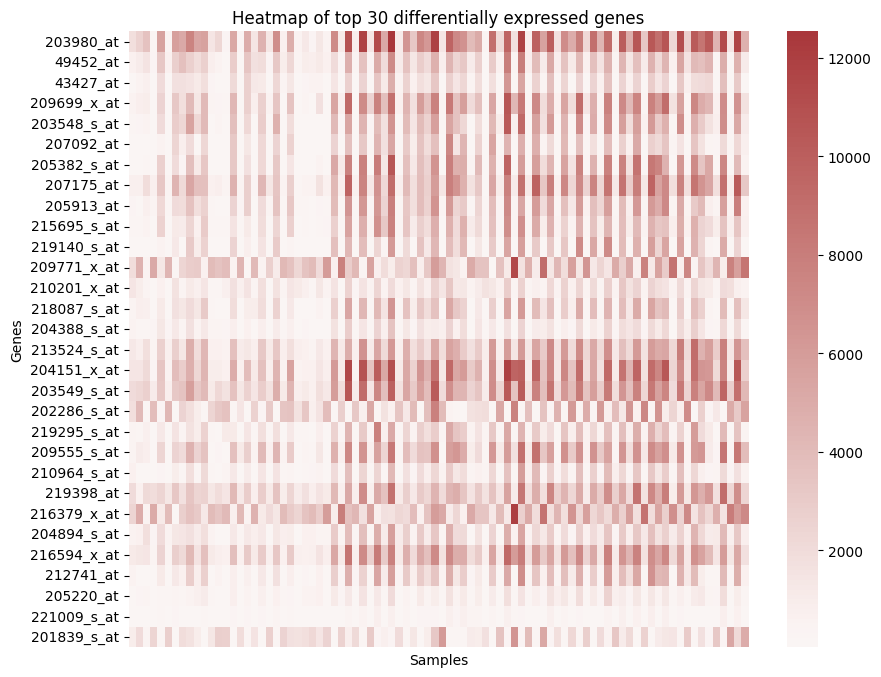

In [ ]:
# heatmap of top 30 differentially expressed genes
top_degs = deg.sort_values("p_adj").head(30)["gene"]
expr_top = df[top_degs].T

plt.figure(figsize=(10, 8))
sns.heatmap(expr_top, cmap="vlag", center=0, xticklabels=False, yticklabels=True)
plt.title("Heatmap of top 30 differentially expressed genes")
plt.xlabel("Samples")
plt.ylabel("Genes")
plt.show()


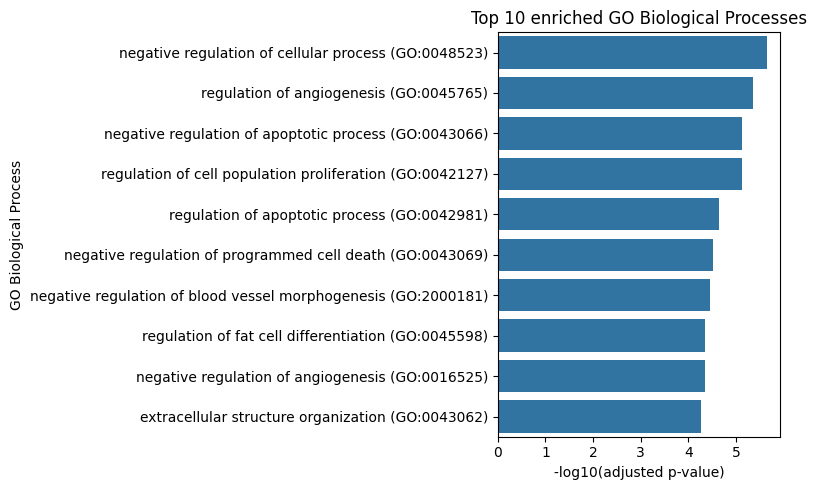

In [ ]:
# bar plot of top 10 enriched GO Biological Processes
top_go = go_significant.sort_values("Adjusted P-value").head(10)

plt.figure(figsize=(8, 5))
sns.barplot(data=top_go, x=-np.log10(top_go["Adjusted P-value"]), y="Term")

plt.xlabel("-log10(adjusted p-value)")
plt.ylabel("GO Biological Process")
plt.title("Top 10 enriched GO Biological Processes")
plt.tight_layout()
plt.show()


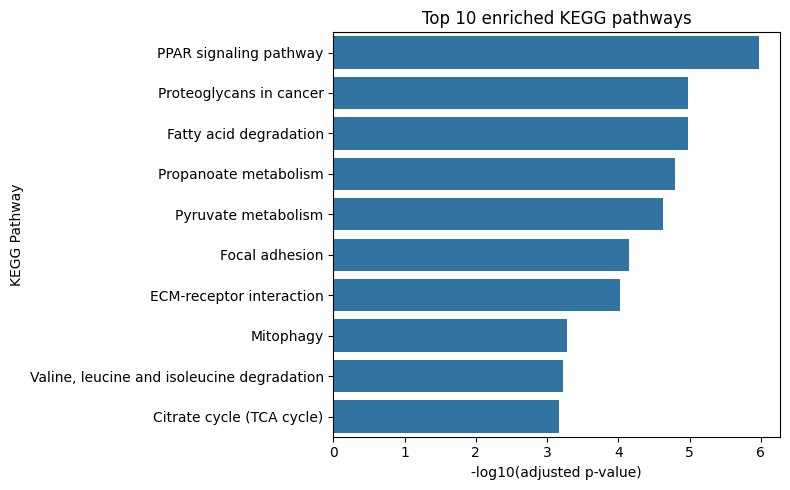

In [ ]:
# bar plot of top 10 enriched KEGG pathways
top_kegg = kegg_significant.sort_values("Adjusted P-value").head(10)

plt.figure(figsize=(8, 5))
sns.barplot(data=top_kegg, x=-np.log10(top_kegg["Adjusted P-value"]), y="Term")
plt.xlabel("-log10(adjusted p-value)")
plt.ylabel("KEGG Pathway")
plt.title("Top 10 enriched KEGG pathways")
plt.tight_layout()
plt.show()
